In [1]:
import tensorflow as tf

print(tf.__version__)

Matplotlib is building the font cache; this may take a moment.


2.21.0


### Implemetation from scratch

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generate regression dataset
X, y = make_regression(
    n_samples=1000,
    n_features=2,
    noise=15,
    random_state=42
)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Scale input features
scaler_X = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

# Scale target values
scaler_y = StandardScaler()

y_train = scaler_y.fit_transform(y_train.reshape(-1, 1))
y_test = scaler_y.transform(y_test.reshape(-1, 1))

print(X_train.shape)
print(y_train.shape)

(800, 2)
(800, 1)


In [3]:
np.random.seed(42)

# Input layer -> Hidden layer
W1 = np.random.randn(2, 3) * 0.01
b1 = np.zeros((1, 3))

# Hidden layer -> Output layer
W2 = np.random.randn(3, 1) * 0.01
b2 = np.zeros((1, 1))

In [4]:
def relu(x):
    return np.maximum(0, x)


def relu_derivative(x):
    return (x > 0).astype(float)


def linear(x):
    return x

In [5]:
def forward_propagation(X):

    Z1 = np.dot(X, W1) + b1

    A1 = relu(Z1)

    Z2 = np.dot(A1, W2) + b2

    A2 = linear(Z2)

    return Z1, A1, Z2, A2

In [6]:
def compute_loss(y, y_pred):

    loss = np.mean((y - y_pred) ** 2)

    return loss

In [7]:
def backward_propagation(X, y, Z1, A1, A2):

    m = X.shape[0]

    # Output layer
    dZ2 = 2 * (A2 - y) / m

    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer
    dZ1 = np.dot(dZ2, W2.T) * relu_derivative(Z1)

    dW1 = np.dot(X.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [8]:
def update_parameters(dW1, db1, dW2, db2, learning_rate):

    global W1, b1, W2, b2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

In [9]:
epochs = 5000
learning_rate = 0.01

loss_history = []

for epoch in range(epochs):

    # Forward propagation
    Z1, A1, Z2, A2 = forward_propagation(X_train)

    # Loss
    loss = compute_loss(y_train, A2)

    # Backpropagation
    dW1, db1, dW2, db2 = backward_propagation(
        X_train, y_train, Z1, A1, A2
    )

    # Update weights
    update_parameters(
        dW1, db1, dW2, db2, learning_rate
    )

    loss_history.append(loss)

    if epoch % 500 == 0:
        print(f"Epoch: {epoch}, Loss: {loss:.6f}")

Epoch: 0, Loss: 0.999928
Epoch: 500, Loss: 0.315715
Epoch: 1000, Loss: 0.170166
Epoch: 1500, Loss: 0.142103
Epoch: 2000, Loss: 0.132451
Epoch: 2500, Loss: 0.127403
Epoch: 3000, Loss: 0.123871
Epoch: 3500, Loss: 0.121543
Epoch: 4000, Loss: 0.119820
Epoch: 4500, Loss: 0.118602


In [10]:
# Predict
_, _, _, predictions = forward_propagation(X_test)

# Convert predictions back to original scale
y_pred = scaler_y.inverse_transform(predictions)
y_actual = scaler_y.inverse_transform(y_test)

# Evaluation
print("MAE:", mean_absolute_error(y_actual, y_pred))

print("MSE:", mean_squared_error(y_actual, y_pred))

print("R2 Score:", r2_score(y_actual, y_pred))

MAE: 12.005124705755753
MSE: 230.96785294921582
R2 Score: 0.8654393747806377


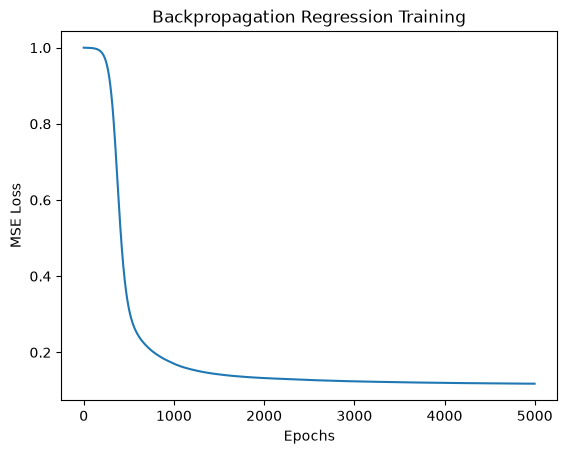

In [11]:
plt.plot(loss_history)

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.title("Backpropagation Regression Training")

plt.show()

### implementation using keras library

In [12]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [13]:
model = Sequential([

    Dense(
        3,
        activation='relu',
        input_shape=(2,)
    ),

    Dense(
        1,
        activation='linear'
    )

])

/Users/imteyazalam/ml-env/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.compile(

    optimizer=tf.keras.optimizers.SGD(
        learning_rate=0.01
    ),

    loss='mean_squared_error',

    metrics=['mae']

)

In [15]:
history = model.fit(

    X_train,
    y_train,

    epochs=5000,

    batch_size=len(X_train),

    verbose=0

)

In [17]:
test_loss, test_mae = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test MAE (scaled):", test_mae)

Test Loss: 0.12370113283395767
Test MAE (scaled): 0.2781592607498169


In [18]:
predictions = model.predict(X_test)

# Convert back to original scale
predictions = scaler_y.inverse_transform(predictions)

actual = scaler_y.inverse_transform(y_test)

print("Predicted values:", predictions[:5].flatten())

print("Actual values:", actual[:5].flatten())

print("R2 Score:", r2_score(actual, predictions))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Predicted values: [ 44.153126   -1.0324267 -24.208862  -15.987669   43.470703 ]
Actual values: [ 29.36339188  -2.09755768 -39.27513549 -30.56782166  40.5436994 ]
R2 Score: 0.8651805125543552


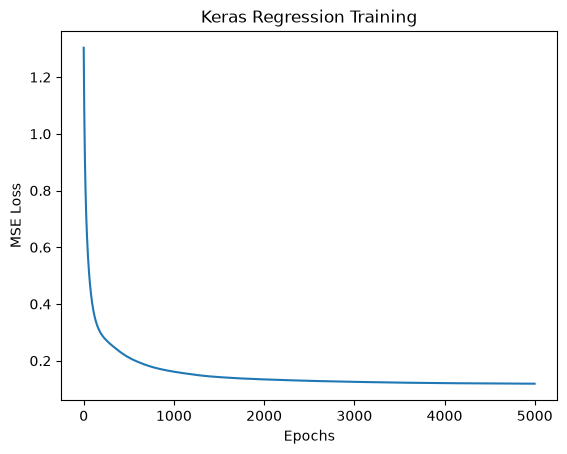

In [19]:
plt.plot(history.history['loss'])

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.title("Keras Regression Training")

plt.show()